In [5]:
import pandas as pd
import numpy as np

df = pd.read_excel("glass.xlsx", sheet_name="glass")

df.head()



,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


# EDA

In [6]:
df.shape

(214, 10)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB


In [8]:
df.isnull().sum()

RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(1)

In [10]:
df = df.drop_duplicates()

df.shape

(213, 10)

In [11]:
df.dtypes

RI      float64
Na      float64
Mg      float64
Al      float64
Si      float64
K       float64
Ca      float64
Ba      float64
Fe      float64
Type      int64
dtype: object

In [12]:
df.describe()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
count,213.000000,213.000000,213.000000,213.000000,213.000000,213.000000,213.000000,213.000000,213.000000,213.000000
mean,1.518348,13.404085,2.679202,1.449484,72.655070,0.498873,8.954085,0.175869,0.057277,2.788732
std,0.003033,0.816662,1.443691,0.495925,0.773998,0.653185,1.425882,0.498245,0.097589,2.105130
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000
25%,1.516520,12.900000,2.090000,1.190000,72.280000,0.130000,8.240000,0.000000,0.000000,1.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.560000,8.600000,0.000000,0.000000,2.000000
75%,1.519150,13.810000,3.600000,1.630000,73.090000,0.610000,9.150000,0.000000,0.100000,3.000000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000


In [13]:
numerical_columns = df.drop(columns=["Type"]).columns

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower) |
        (df[column] > upper)
    ]

    print(column, ":", len(outliers))

RI : 17
Na : 7
Mg : 0
Al : 17
Si : 12
K : 7
Ca : 27
Ba : 38
Fe : 12


# Data Visualisation

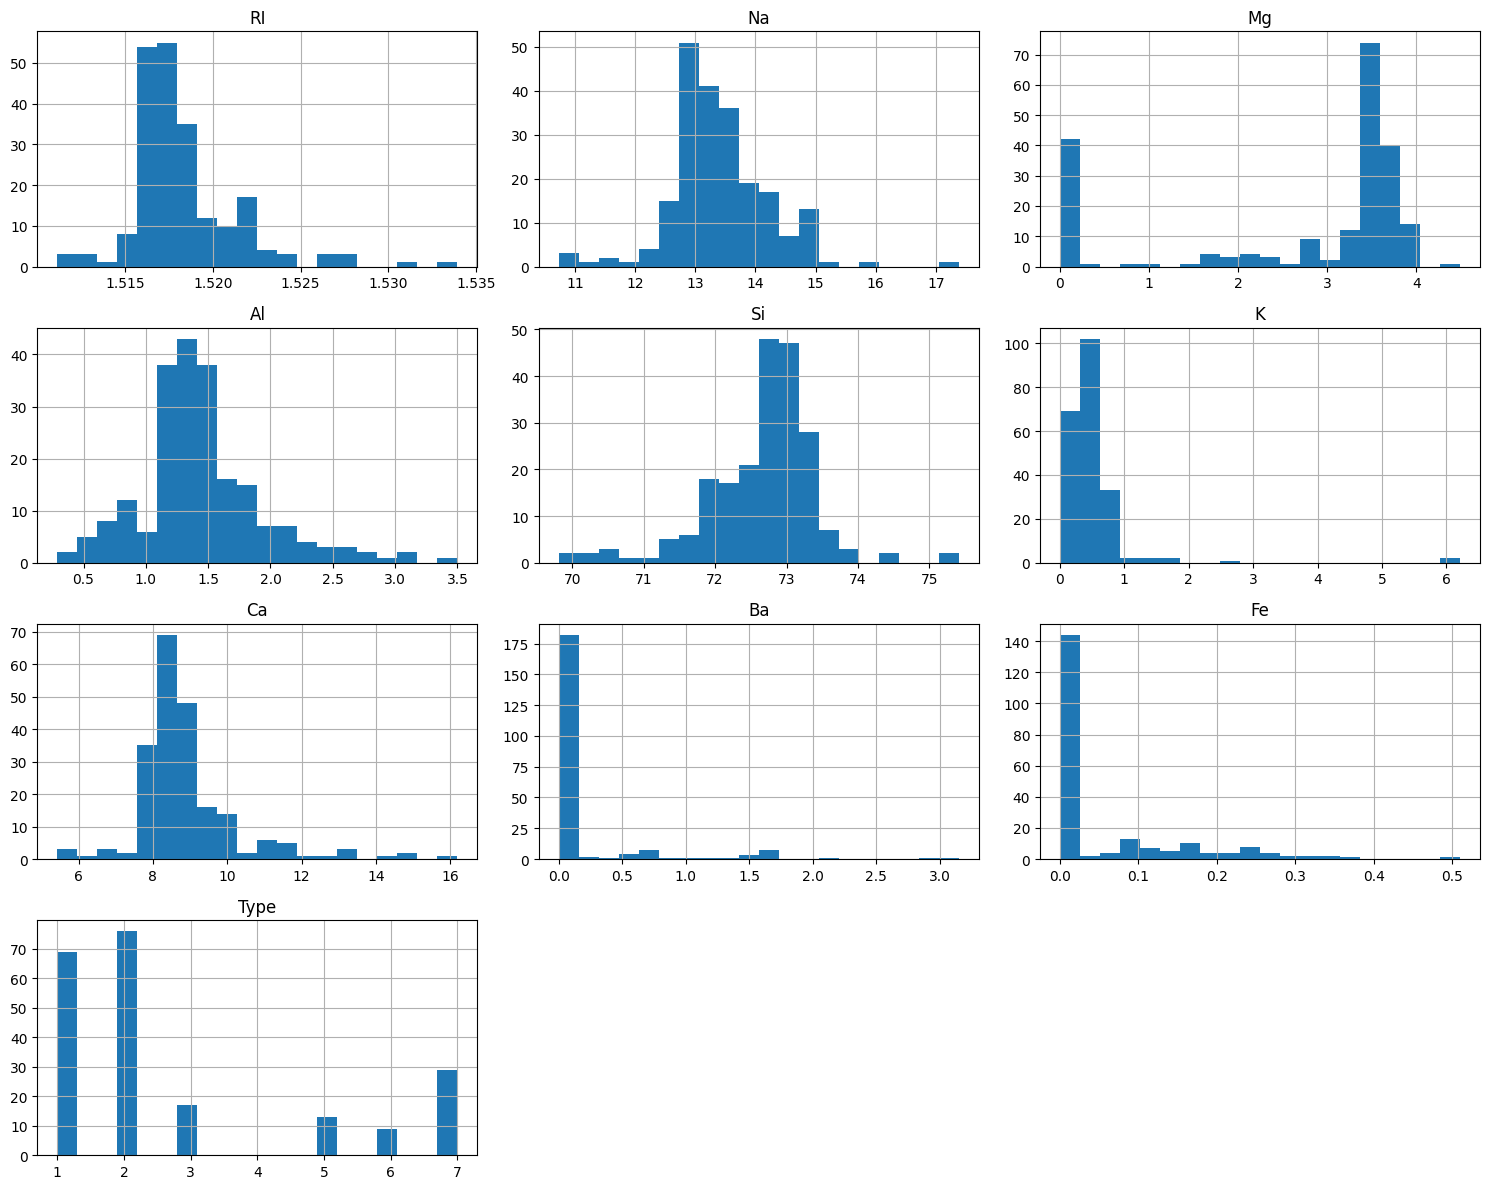

In [16]:

import matplotlib.pyplot as plt
#histogram
df.hist(
    figsize=(15, 12),
    bins=20
)

plt.tight_layout()
plt.show()

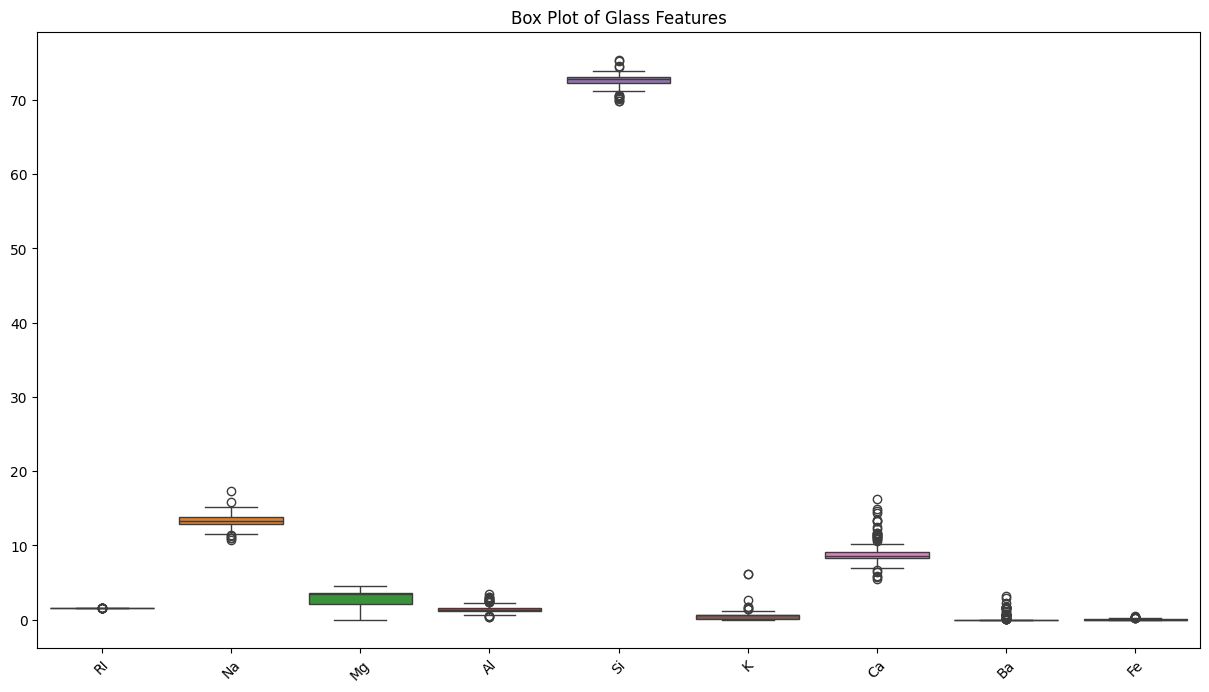

In [17]:
#boxplot
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))

sns.boxplot(
    data=df.drop(columns=["Type"])
)

plt.xticks(rotation=45)
plt.title("Box Plot of Glass Features")
plt.show()

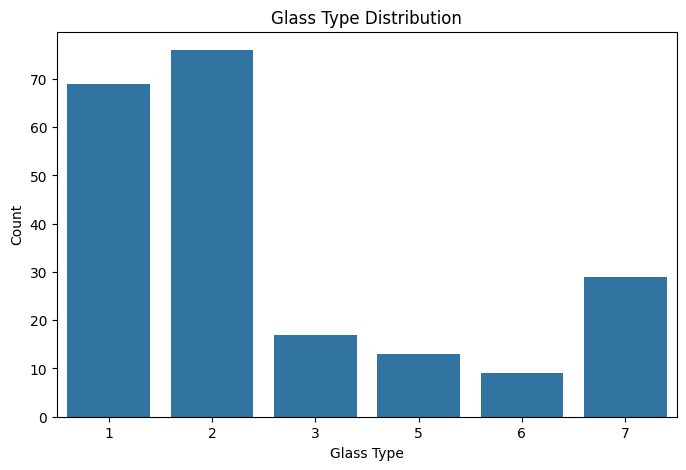

In [18]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Type"
)

plt.title("Glass Type Distribution")
plt.xlabel("Glass Type")
plt.ylabel("Count")

plt.show()

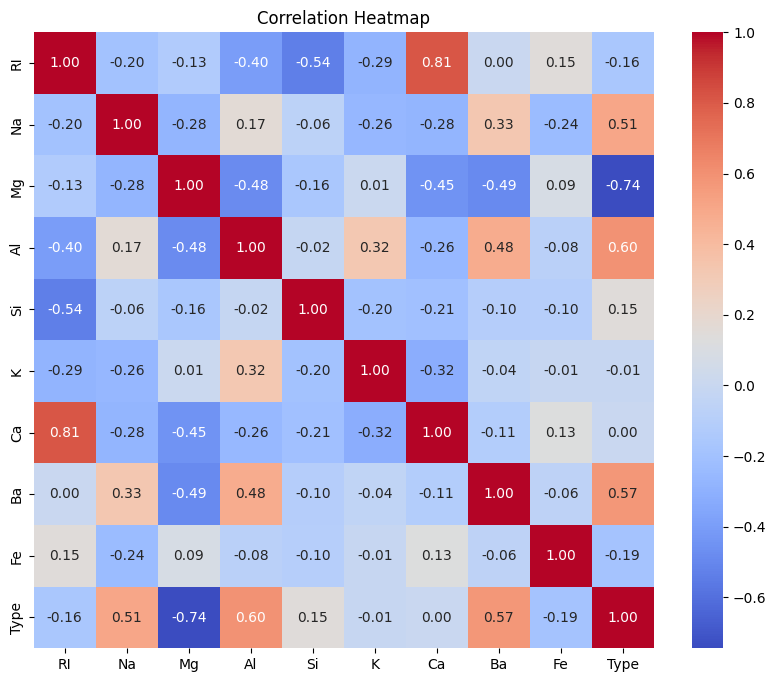

In [19]:
#correlation analysis
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

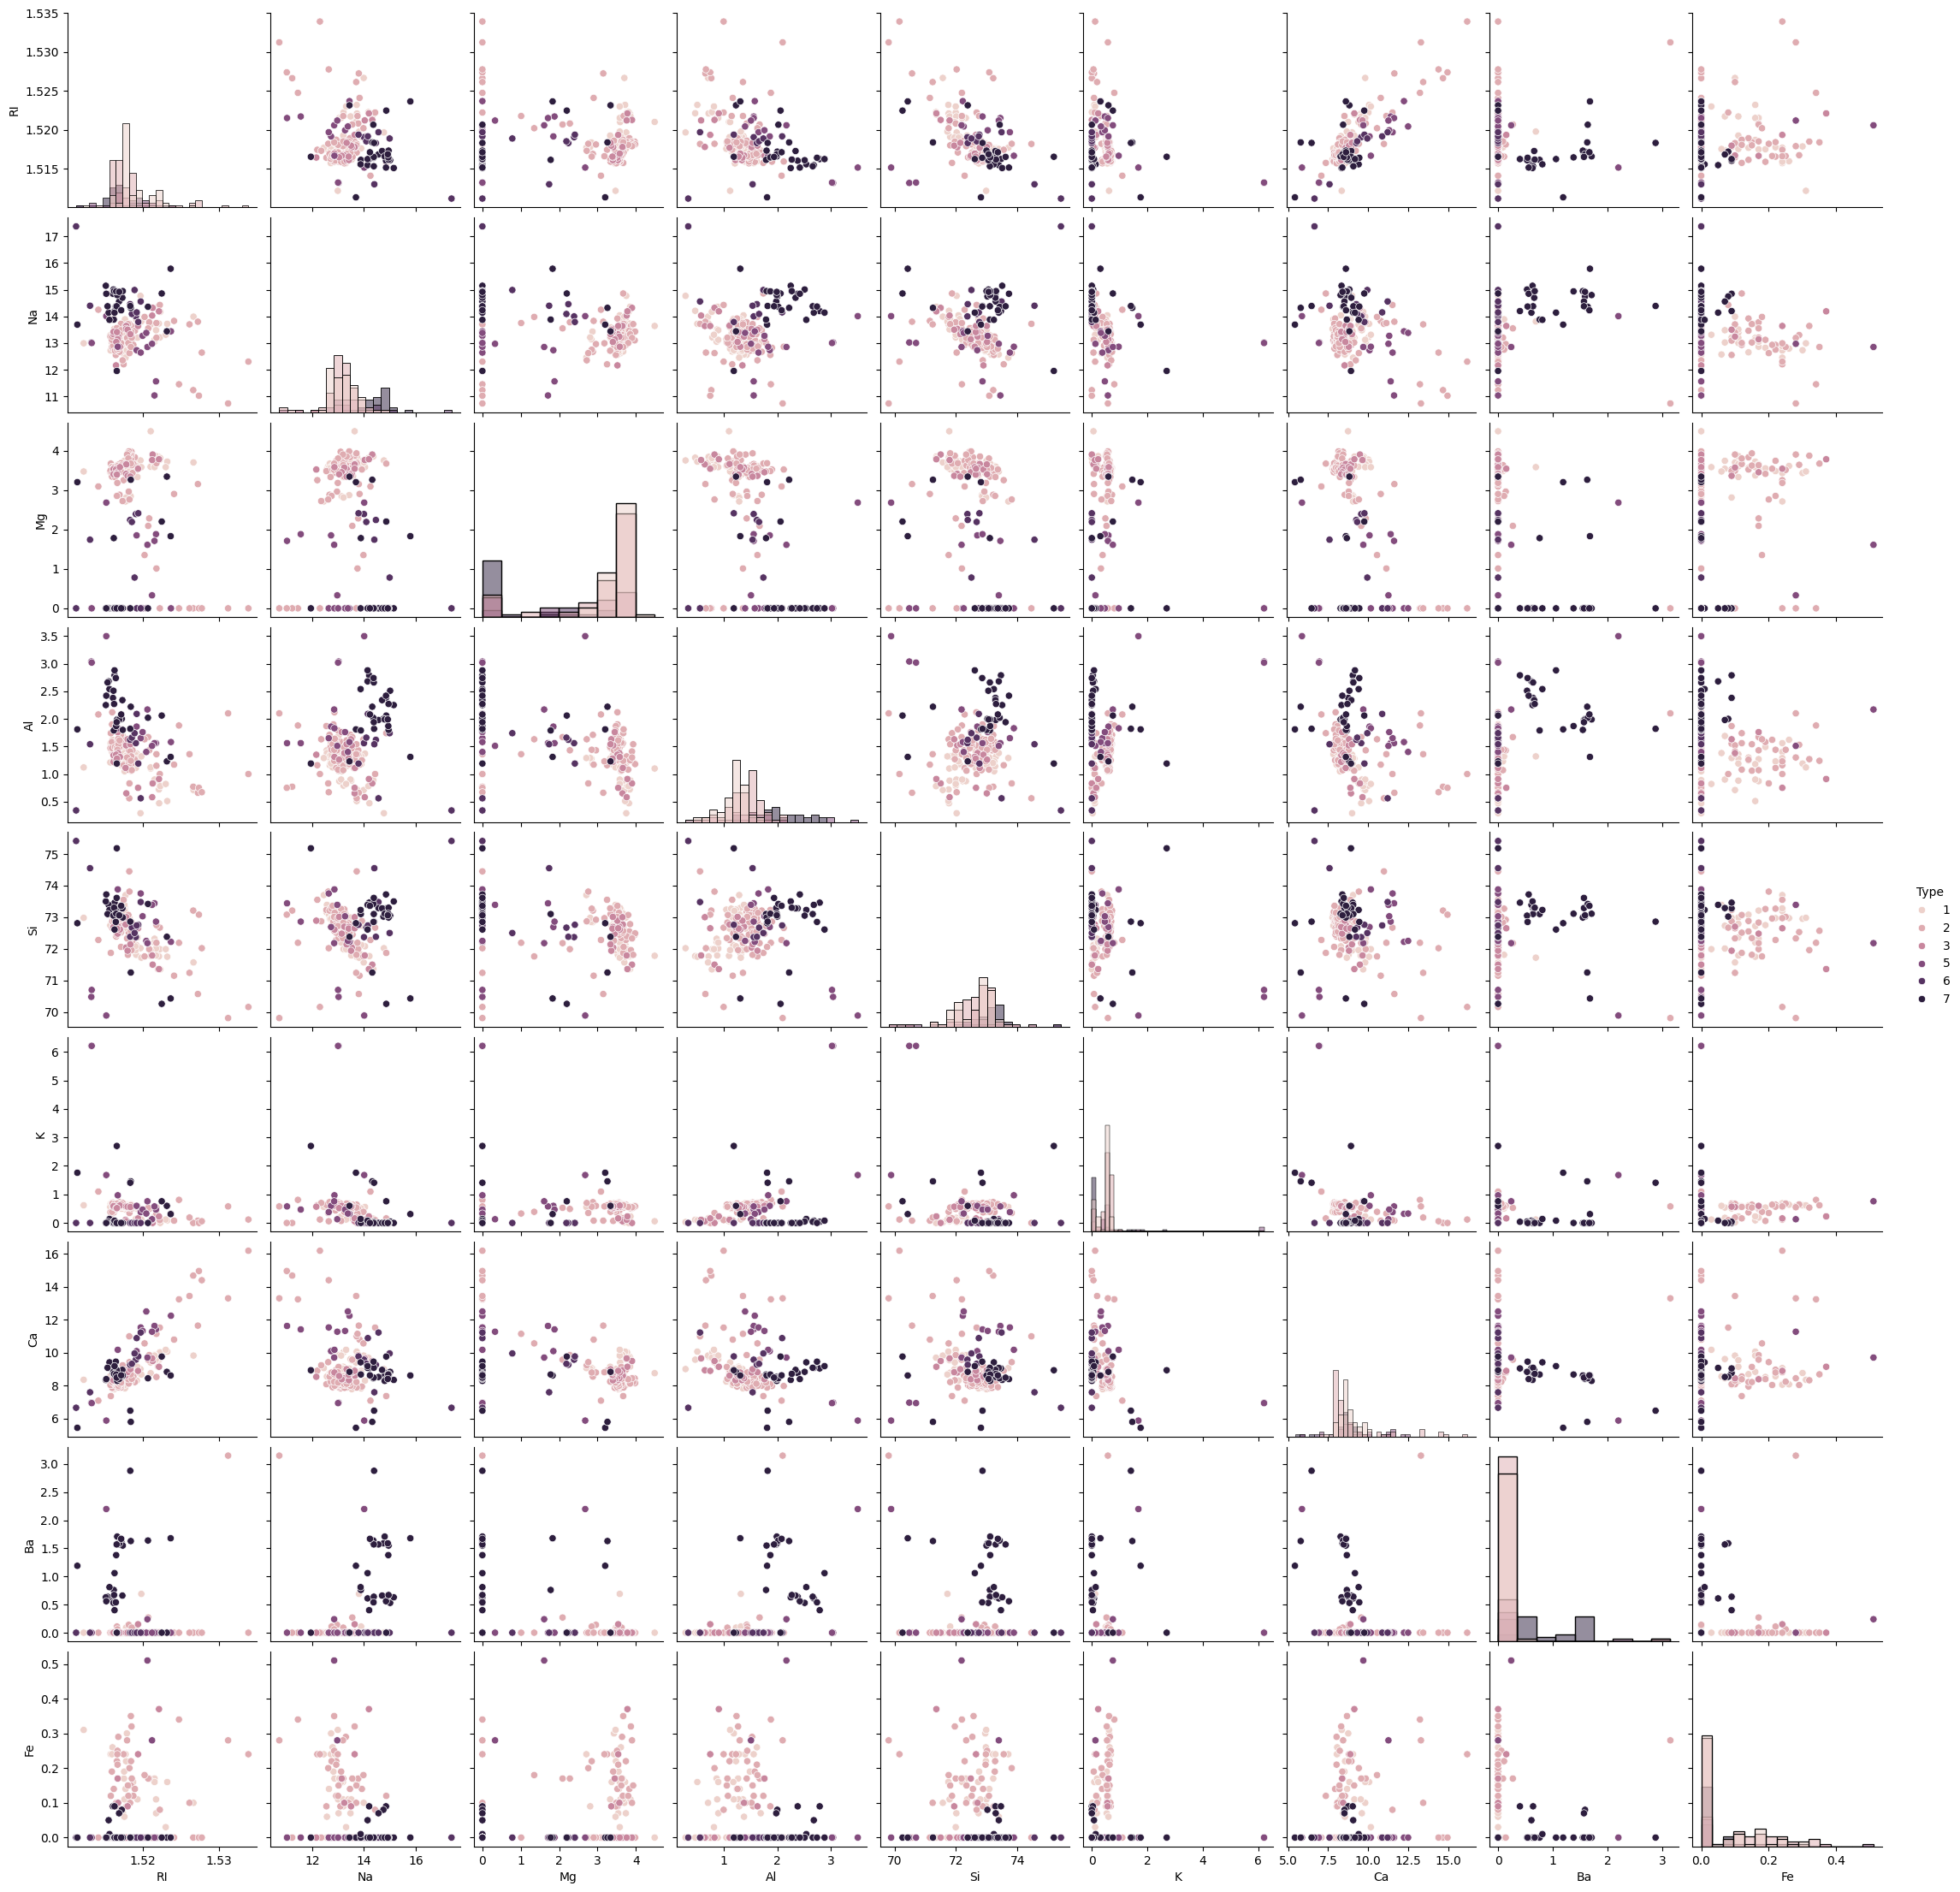

In [20]:
#pair plot
sns.pairplot(
    df,
    hue="Type",
    diag_kind="hist"
)

plt.show()

# Data Preprocessing

In [21]:
X = df.drop(columns=["Type"])
y = df["Type"]

In [22]:
X.select_dtypes(include="object").columns

Index([], dtype='object')

In [23]:
#feature scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Random Forest Model implementation

In [25]:

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [26]:
y_pred = rf_model.predict(X_test)

In [27]:
#Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.7906976744186046
Precision: 0.8100775193798448
Recall   : 0.7906976744186046
F1 Score : 0.7919661733615222


In [28]:
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           1       0.75      0.86      0.80        14
           2       0.73      0.73      0.73        15
           3       1.00      0.67      0.80         3
           5       1.00      0.67      0.80         3
           6       0.67      1.00      0.80         2
           7       1.00      0.83      0.91         6

    accuracy                           0.79        43
   macro avg       0.86      0.79      0.81        43
weighted avg       0.81      0.79      0.79        43



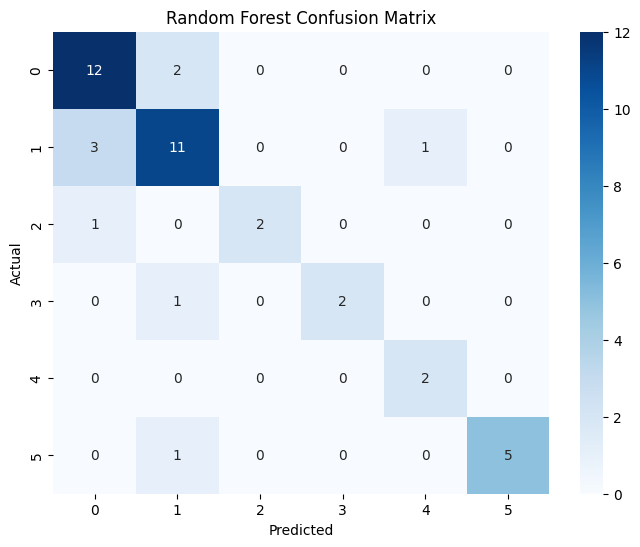

In [29]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

In [30]:
#feature importance
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

  Feature  Importance
2      Mg    0.170191
6      Ca    0.141457
1      Na    0.134147
5       K    0.131605
3      Al    0.122035
0      RI    0.110630
4      Si    0.084206
7      Ba    0.082361
8      Fe    0.023368


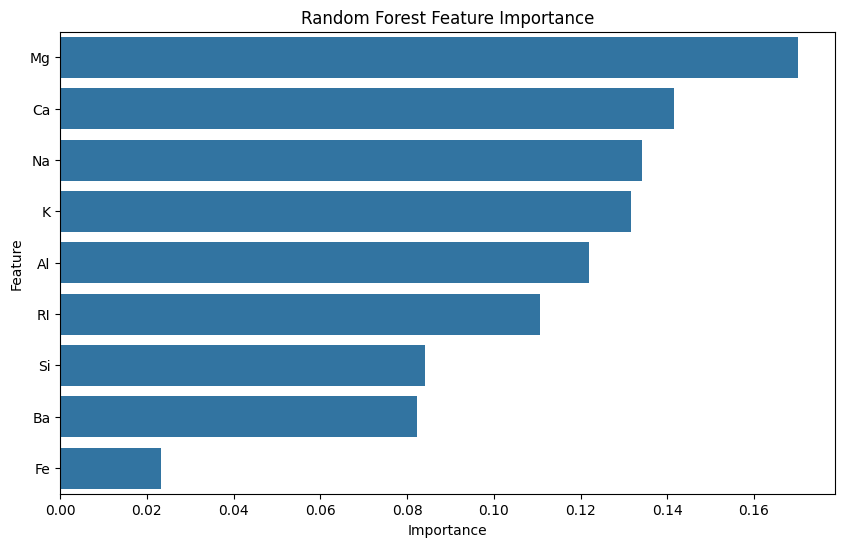

In [31]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.show()

# Bagging and Boosting Methods

In [36]:
#implementing bagging method
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=300,
    random_state=42
)

bagging_model.fit(X_train, y_train)

bagging_pred = bagging_model.predict(X_test)

In [37]:
bagging_accuracy = accuracy_score(
    y_test,
    bagging_pred
)

bagging_precision = precision_score(
    y_test,
    bagging_pred,
    average="weighted",
    zero_division=0
)

bagging_recall = recall_score(
    y_test,
    bagging_pred,
    average="weighted",
    zero_division=0
)

bagging_f1 = f1_score(
    y_test,
    bagging_pred,
    average="weighted",
    zero_division=0
)

print("Accuracy :", bagging_accuracy)
print("Precision:", bagging_precision)
print("Recall   :", bagging_recall)
print("F1 Score :", bagging_f1)

Accuracy : 0.813953488372093
Precision: 0.8214498679614959
Recall   : 0.813953488372093
F1 Score : 0.812694626648115


In [38]:
#implementing boosting method
from sklearn.ensemble import AdaBoostClassifier

boosting_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    n_estimators=200,
    random_state=42
)

boosting_model.fit(X_train, y_train)

boosting_pred = boosting_model.predict(X_test)

In [39]:
boosting_accuracy = accuracy_score(
    y_test,
    boosting_pred
)

boosting_precision = precision_score(
    y_test,
    boosting_pred,
    average="weighted",
    zero_division=0
)

boosting_recall = recall_score(
    y_test,
    boosting_pred,
    average="weighted",
    zero_division=0
)

boosting_f1 = f1_score(
    y_test,
    boosting_pred,
    average="weighted",
    zero_division=0
)

print("Accuracy :", boosting_accuracy)
print("Precision:", boosting_precision)
print("Recall   :", boosting_recall)
print("F1 Score :", boosting_f1)

Accuracy : 0.4186046511627907
Precision: 0.4797568710359409
Recall   : 0.4186046511627907
F1 Score : 0.42005218749404793


#### 1. Explain Bagging and Boosting methods. How are they different?
Bagging creates multiple independent models using different bootstrap samples and combines their predictions. It mainly helps reduce variance and overfitting. Random Forest is an example of a Bagging-based ensemble method.

Boosting creates models sequentially, where each new model attempts to improve the errors made by previous models. Examples include AdaBoost, Gradient Boosting, XGBoost, and LightGBM.

The main difference is that Bagging trains models independently, whereas Boosting trains models sequentially and focuses on previous errors.
    
#### 2. Explain how to handle imbalance in the data.

For imbalanced data, techniques such as stratified sampling, class weighting, oversampling using SMOTE, and undersampling can be used. In addition, metrics such as precision, recall, F1-score, and the confusion matrix should be considered instead of relying only on accuracy. For the Glass dataset, stratified splitting combined with class_weight="balanced" in Random Forest is a practical approach.